# Capítulo 5 · Proyecto 1: comparación de modelos

> ¿Qué modelo recomendarías para clasificar la presencia de enfermedad cardiaca y qué resultados respaldan tu elección?

Utiliza el dataset [UCI Heart Disease de Kaggle](https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data), archivo `heart_disease_uci.csv`, y documenta tu trabajo en un notebook reproducible.

## Etapa 1: limpieza y preparación

1. Identifica los valores faltantes y los valores inválidos, decide cómo tratarlos y justifica brevemente tu decisión.
2. Explora los posibles outliers y explica si los conservarás o aplicarás algún tratamiento.
3. Prepara las variables numéricas y categóricas. Crea el objetivo binario (**target**) a partir de `num`: **target = 0 si num = 0** (ausencia de enfermedad) y **target = 1 si num es 1, 2, 3 o 4** (presencia de enfermedad). Excluye tanto `num` como el target de las entradas del modelo.

## Etapa 2: entrenamiento y comparación

1. Separa los datos en entrenamiento, validación y prueba, usando las mismas particiones para todos los modelos y `random_state=42`. Ajusta la imputación y el escalado únicamente con entrenamiento.
2. Entrena **regresión logística, KNN y árbol de decisión**, aplicando escalado cuando corresponda.
3. Usa **GridSearchCV** con validación cruzada sobre los datos de entrenamiento para buscar los mejores hiperparámetros de los tres modelos. Compara las mejores configuraciones en validación y selecciona el modelo con mejor resultado según una métrica justificada.
4. Compara entrenamiento y evaluación para identificar sobreajuste. Presenta una tabla de métricas y las matrices de confusión de prueba.
5. Recomienda un modelo y justifica tu elección con los resultados: qué errores comete, qué ventajas tiene y cuáles son sus limitaciones.

In [92]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import KFold
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, roc_curve
from scipy.stats.contingency import association
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "heart_disease_uci.csv")
df.head()


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


| Nombre original | Significado en español |
|---|---|
| `id` | Identificador del registro |
| `age` | Edad |
| `sex` | Sexo |
| `dataset` | Origen de los datos |
| `cp` | Tipo de dolor torácico |
| `trestbps` | Presión arterial en reposo |
| `chol` | Colesterol |
| `fbs` | Glucosa en ayunas superior a 120 mg/dL |
| `restecg` | Resultado del electrocardiograma en reposo |
| `thalch` | Frecuencia cardíaca máxima alcanzada |
| `exang` | Angina provocada por el ejercicio |
| `oldpeak` | Descenso del segmento ST durante el ejercicio respecto al reposo |
| `slope` | Pendiente del segmento ST durante el máximo esfuerzo |
| `ca` | Número de vasos principales observados por fluoroscopia |
| `thal` | Resultado de la prueba de talio |
| `num` | Diagnóstico: 0 indica ausencia de enfermedad; 1–4 indican presencia |

In [93]:
# tu codigo aqui
print ("Filas y columnas del dataset: ", df.shape)
df.info()

Filas y columnas del dataset:  (920, 16)
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [94]:
nulos = df.isna().sum()
nulos[nulos > 0]

trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
dtype: int64

In [95]:
porcentaje_nulos = nulos[nulos > 0] / len(df) * 100
porcentaje_nulos.sort_values(ascending=False).round(2)

ca          66.41
thal        52.83
slope       33.59
fbs          9.78
oldpeak      6.74
trestbps     6.41
exang        5.98
thalch       5.98
chol         3.26
restecg      0.22
dtype: float64

In [96]:
df.duplicated().sum()

np.int64(0)

el id no nos sirve de nada, lo borramos de una

In [97]:
df = df.drop(columns=["id"])

In [98]:
df["target"] = (df["num"] > 0).astype(int)
print(df["num"].value_counts().sort_index())
print()
print(df["target"].value_counts(normalize=True).round(3))

#en target 1 = enfermo 0 = sano

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

target
1    0.553
0    0.447
Name: proportion, dtype: float64


In [99]:
numeric_columns = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
age,920.0,53.510870,9.424685,28.0,47.0,54.0,60.0,77.0
trestbps,861.0,132.132404,19.066070,0.0,120.0,130.0,140.0,200.0
chol,890.0,199.130337,110.780810,0.0,175.0,223.0,268.0,603.0
thalch,865.0,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.0,0.5,1.5,6.2
ca,309.0,0.676375,0.935653,0.0,0.0,0.0,1.0,3.0


In [100]:
(df[["trestbps", "chol"]] == 0).sum()

trestbps      1
chol        172
dtype: int64

In [101]:
(df[["oldpeak"]] < 0).sum()

oldpeak    12
dtype: int64

In [102]:
# Mostrar los registros con oldpeak negativo
df.loc[
    df["oldpeak"] < 0,
    ["dataset", "oldpeak", "slope"]
].sort_values("oldpeak")

,dataset,oldpeak,slope
615,Switzerland,-2.6,flat
653,Switzerland,-2.0,flat
609,Switzerland,-1.5,downsloping
603,Switzerland,-1.1,upsloping
656,Switzerland,-1.0,downsloping
655,Switzerland,-1.0,upsloping
696,Switzerland,-0.9,flat
691,Switzerland,-0.8,flat
629,Switzerland,-0.7,upsloping
694,Switzerland,-0.5,flat


In [103]:
# Marcar los ceros de presión y colesterol como valores faltantes
columns_to_clean = ["trestbps", "chol"]

df[columns_to_clean] = df[columns_to_clean].replace(0, np.nan)

# Comprobar cuántos valores faltantes hay ahora
df[columns_to_clean].isna().sum()

trestbps     60
chol        202
dtype: int64

In [104]:
categorical_columns = [
    "sex", "dataset", "cp", "fbs",
    "restecg", "exang", "slope", "thal"
]

for column in categorical_columns:
    print(f"\nColumna: {column}")
    print(df[column].value_counts(dropna=False))


Columna: sex
sex
Male      726
Female    194
Name: count, dtype: int64

Columna: dataset
dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

Columna: cp
cp
asymptomatic       496
non-anginal        204
atypical angina    174
typical angina      46
Name: count, dtype: int64

Columna: fbs
fbs
False    692
True     138
NaN       90
Name: count, dtype: int64

Columna: restecg
restecg
normal              551
lv hypertrophy      188
st-t abnormality    179
NaN                   2
Name: count, dtype: int64

Columna: exang
exang
False    528
True     337
NaN       55
Name: count, dtype: int64

Columna: slope
slope
flat           345
NaN            309
upsloping      203
downsloping     63
Name: count, dtype: int64

Columna: thal
thal
NaN                  486
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64


,variable,min,Q1,mediana,Q3,max,lim_inf_IQR,lim_sup_IQR,outliers_IQR,outliers_Z>3,asimetria_skew
0,age,28.0,47.0,54.0,60.00,77.0,27.50,79.50,0,0,-0.20
1,trestbps,80.0,120.0,130.0,140.00,200.0,90.00,170.00,27,7,0.63
2,chol,85.0,210.0,239.5,276.75,603.0,109.88,376.88,23,8,1.31
3,thalch,60.0,120.0,140.0,157.00,202.0,64.50,212.50,2,0,-0.21
4,oldpeak,-2.6,0.0,0.5,1.50,6.2,-2.25,3.75,16,7,1.04


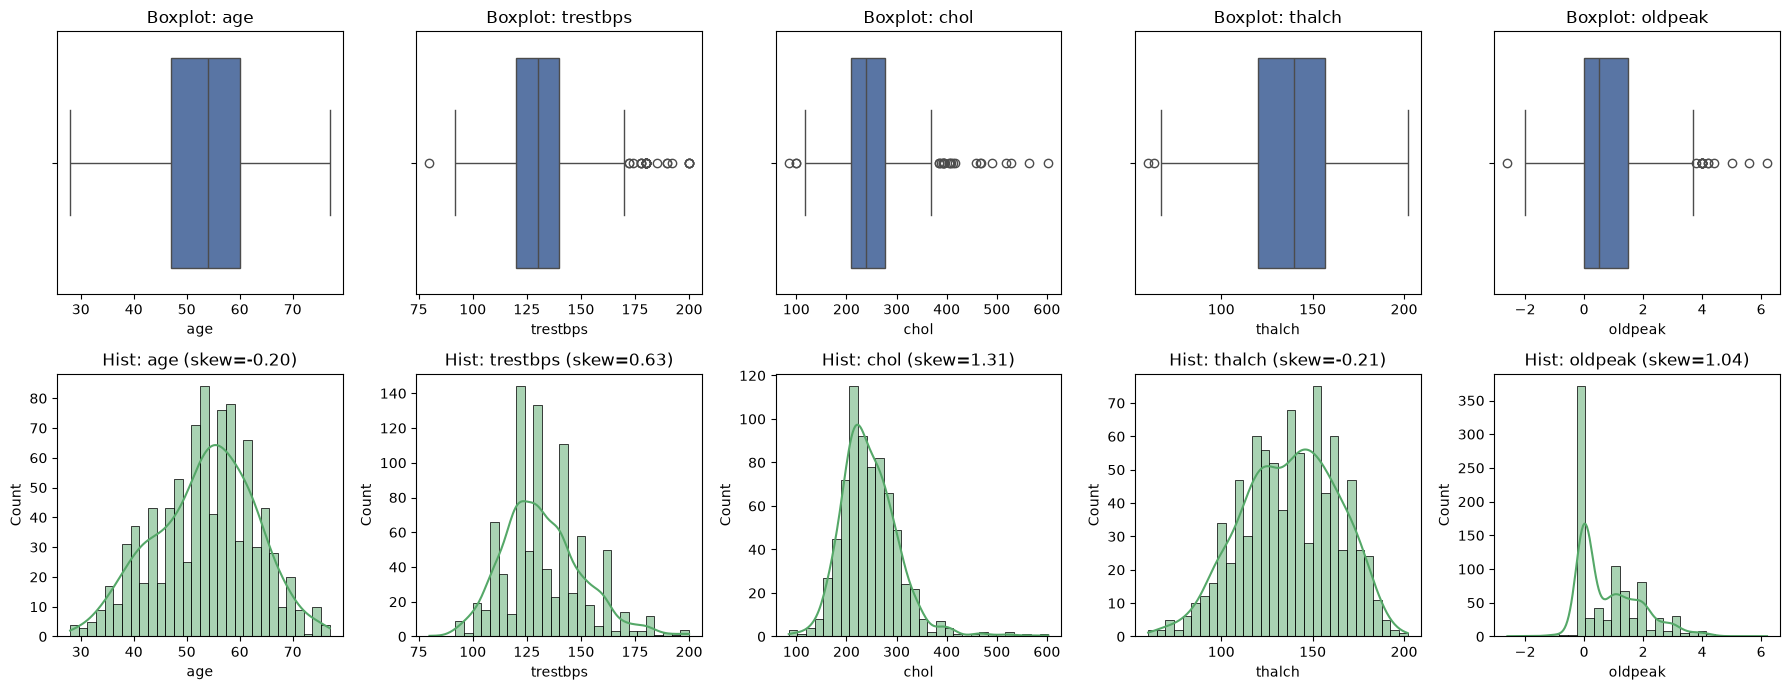

In [105]:
cols_num_continuas = ["age", "trestbps", "chol", "thalch", "oldpeak"]

def detectar_outliers_resumen(dataframe, columnas, k=1.5):
    """Calcula límites IQR, conteo de outliers por IQR y Z-score, y asimetría."""
    resultados = []
    for col in columnas:
        serie = dataframe[col].dropna()
        q1, q3 = serie.quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - k * iqr, q3 + k * iqr
        out_iqr = ((serie < lim_inf) | (serie > lim_sup)).sum()
        z_scores = (serie - serie.mean()) / serie.std()
        out_z = (z_scores.abs() > 3).sum()
        
        resultados.append({
            "variable": col,
            "min": serie.min(),
            "Q1": q1,
            "mediana": serie.median(),
            "Q3": q3,
            "max": serie.max(),
            "lim_inf_IQR": round(lim_inf, 2),
            "lim_sup_IQR": round(lim_sup, 2),
            "outliers_IQR": out_iqr,
            "outliers_Z>3": out_z,
            "asimetria_skew": round(serie.skew(), 2)
        })
    return pd.DataFrame(resultados)

tabla_outliers = detectar_outliers_resumen(df, cols_num_continuas)
display(tabla_outliers)

# Visualización con Boxplots e Histogramas
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for i, col in enumerate(cols_num_continuas):
    sns.boxplot(x=df[col], ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"Boxplot: {col}")
    
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=axes[1, i], color="#55A868")
    axes[1, i].set_title(f"Hist: {col} (skew={df[col].skew():.2f})")

plt.tight_layout()
plt.show()

In [106]:
# Respuesta que queremos predecir
y = df["target"]

# Características disponibles para hacer la predicción
X = df.drop(columns=["id", "num", "target"], errors="ignore")

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Variables de entrada:", X.columns.tolist())

Dimensiones de X: (920, 14)
Dimensiones de y: (920,)
Variables de entrada: ['age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [107]:
# Reservar el 60 % para entrenamiento y el 40 % restante
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=42
)

# Dividir ese 40 % en dos partes iguales: validación y prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (552, 14)
Validación: (184, 14)
Prueba: (184, 14)


In [108]:
numeric_columns = [
    "age", "trestbps", "chol", "thalch", "oldpeak", "ca"
]

categorical_columns = [
    "sex", "dataset", "cp", "fbs",
    "restecg", "exang", "slope", "thal"
]

# Preparación de las variables numéricas
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preparación de las variables categóricas
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Aplicar a cada grupo su preparación correspondiente
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

In [109]:
# Unir la preparación de datos y el modelo
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# Validación cruzada dentro del conjunto de entrenamiento
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Probar diferentes intensidades de regularización
logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid={"model__C": [0.01, 0.1, 1, 10, 100]},
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

logistic_search.fit(X_train, y_train)

# Evaluar la mejor configuración en validación
val_pred_logistic = logistic_search.predict(X_val)

print("Mejores parámetros:", logistic_search.best_params_)
print(f"F1 promedio en validación cruzada: {logistic_search.best_score_:.3f}")
print(f"F1 en validación: {f1_score(y_val, val_pred_logistic):.3f}")

Mejores parámetros: {'model__C': 0.1}
F1 promedio en validación cruzada: 0.847
F1 en validación: 0.859


In [110]:
# Unir la preparación de datos y KNN
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier())
])

knn_params = {
    "model__n_neighbors": [2, 3, 4, 5, 7, 11, 13, 15, 21],
    "model__weights": ["uniform", "distance"]
}

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

# Evaluar la mejor configuración en validación
val_pred_knn = knn_search.predict(X_val)

print("Mejores parámetros:", knn_search.best_params_)
print(f"F1 promedio en validación cruzada: {knn_search.best_score_:.3f}")
print(f"F1 en validación: {f1_score(y_val, val_pred_knn):.3f}")

Mejores parámetros: {'model__n_neighbors': 15, 'model__weights': 'distance'}
F1 promedio en validación cruzada: 0.851
F1 en validación: 0.856


In [111]:
# Preparación para el árbol, sin escalado
tree_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

tree_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

tree_params = {
    "model__max_depth": [None, 3, 5, 7, 10],
    "model__min_samples_leaf": [1, 5, 10]
}

tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

tree_search.fit(X_train, y_train)

# Evaluar la mejor configuración en validación
val_pred_tree = tree_search.predict(X_val)

print("Mejores parámetros:", tree_search.best_params_)
print(f"F1 promedio en validación cruzada: {tree_search.best_score_:.3f}")
print(f"F1 en validación: {f1_score(y_val, val_pred_tree):.3f}")

Mejores parámetros: {'model__max_depth': 5, 'model__min_samples_leaf': 5}
F1 promedio en validación cruzada: 0.796
F1 en validación: 0.798


In [112]:
models = {
    "Regresión logística": logistic_search.best_estimator_,
    "KNN": knn_search.best_estimator_,
    "Árbol de decisión": tree_search.best_estimator_
}

results = []
test_predictions = {}

for name, model in models.items():
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    # Guardar las predicciones para las matrices de confusión
    test_predictions[name] = test_pred

    results.append({
        "Modelo": name,
        "F1 entrenamiento": f1_score(y_train, train_pred),
        "F1 validación": f1_score(y_val, val_pred),
        "F1 prueba": f1_score(y_test, test_pred),
        "Accuracy prueba": accuracy_score(y_test, test_pred),
        "Precisión prueba": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "Recall prueba": recall_score(
            y_test, test_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Modelo")
results_df.round(3)

,F1 entrenamiento,F1 validación,F1 prueba,Accuracy prueba,Precisión prueba,Recall prueba
Modelo,,,,,,
Regresión logística,0.867,0.859,0.837,0.821,0.842,0.833
KNN,1.000,0.856,0.828,0.810,0.832,0.824
Árbol de decisión,0.867,0.798,0.773,0.761,0.815,0.735


In [113]:
for name, predictions in test_predictions.items():
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])

    table = pd.DataFrame(
        matrix,
        index=["Real: sin enfermedad (0)", "Real: con enfermedad (1)"],
        columns=[
            "Predicción: sin enfermedad (0)",
            "Predicción: con enfermedad (1)"
        ]
    )

    print(name)
    display(table)

Regresión logística


,Predicción: sin enfermedad (0),Predicción: con enfermedad (1)
Real: sin enfermedad (0),66,16
Real: con enfermedad (1),17,85


KNN


,Predicción: sin enfermedad (0),Predicción: con enfermedad (1)
Real: sin enfermedad (0),65,17
Real: con enfermedad (1),18,84


Árbol de decisión


,Predicción: sin enfermedad (0),Predicción: con enfermedad (1)
Real: sin enfermedad (0),65,17
Real: con enfermedad (1),27,75


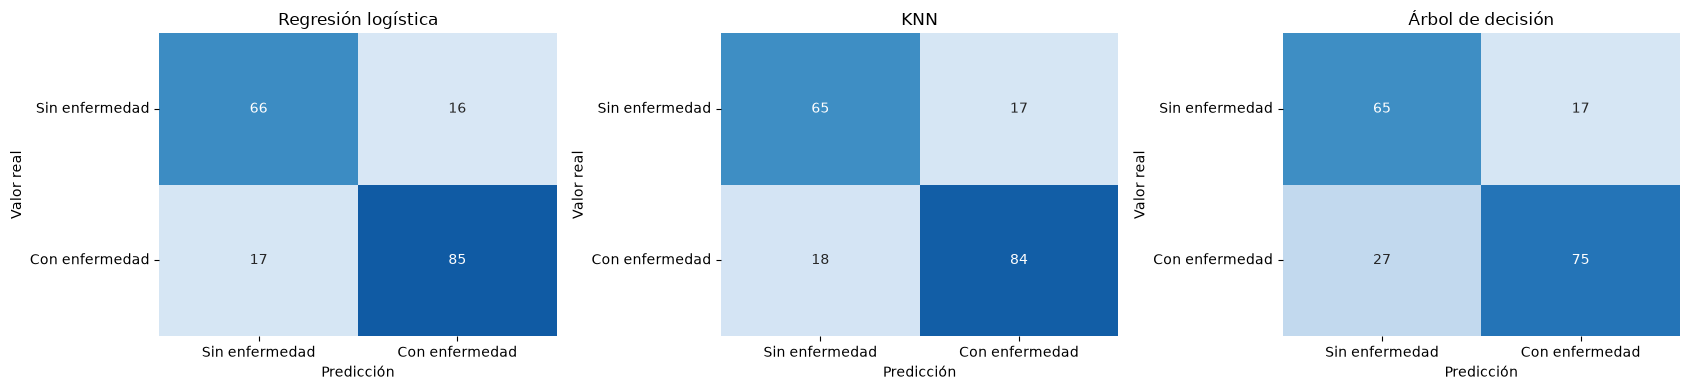

In [115]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
class_names = ["Sin enfermedad", "Con enfermedad"]

for ax, (name, predictions) in zip(axes, test_predictions.items()):
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        vmin=0,
        vmax=y_test.value_counts().max(),
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()